# Notebook 4: Đánh Giá Định Lượng & Phân Tích Trường Hợp Thất Bại
**Căn cứ tài liệu:** `docs/KHUNG_NOI_DUNG_TONG_QUAT_DO_AN_XLAS.md`  
* **Quy trình chuẩn Bộ môn:**  
  * **Bước 5 — Xây dựng Baseline & Thực nghiệm so sánh (Comparative Experiments)**
  * **Bước 6 — Đánh giá định lượng & Phân tích trường hợp thất bại (Evaluation & Error Analysis)**
* **Ánh xạ Báo cáo đồ án:** **Mục 6 — Kết quả và đánh giá**  
* **Học phần:** Xử lý ảnh số (2026–2027) — Khoa CNTT — Trường ĐH Công Thương TP.HCM (HUIT)  
* **Nhóm thực hiện:** Hà Mạnh Trường (2045240326) & Huỳnh Tâm Trí (2045240315) — *Trí phụ trách chính*

---

## 1. Bộ đo định lượng y khoa chuẩn mực (Theo Khung Tổng Quát Mục II.6 & IV)
1. **Dice Similarity Coefficient (DSC / F1):** $\text{Dice} = \frac{2|P \cap G|}{|P| + |G|}$
2. **Jaccard Index (IoU):** $\text{IoU} = \frac{|P \cap G|}{|P \cup G|} = \frac{\text{Dice}}{2 - \text{Dice}}$
3. **Độ nhạy (Sensitivity / Recall):** $\text{Sensitivity} = \frac{\text{TP}}{\text{TP} + \text{FN}}$ (Đo khả năng không bỏ sót pixel u)
4. **Độ đặc hiệu (Specificity):** $\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}$ (Đo khả năng không nhận nhầm não lành)
5. **Độ trễ tính toán:** Thời gian xử lý trung bình trên từng khung hình/ảnh (Latency ms).

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

sys.path.append(os.path.abspath('..'))
from src.preprocessing.skull_strip import strip_skull
from src.segmentation.watershed import segment_watershed
from src.segmentation.region_growing import segment_region_growing
from src.evaluation.benchmark import run_benchmark
base_dir = "../data/full"
img_dir = os.path.join(base_dir, 'images')
mask_dir = os.path.join(base_dir, 'masks')
print(f'Sẵn sàng thực thi benchmark trên tập dữ liệu: {base_dir} ({len(os.listdir(img_dir))} lát cắt)...')

Sẵn sàng thực thi benchmark trên tập dữ liệu: ../data/full (3929 lát cắt)...


## 2. Chạy Thực Nghiệm Đánh Giá Hàng Loạt (Batch Benchmark) 20 Mẫu

In [2]:
def predict_ws(img):
    stripped, _ = strip_skull(img)
    return segment_watershed(stripped, dist_thresh_ratio=0.4)

def predict_rg(img):
    stripped, _ = strip_skull(img)
    return segment_region_growing(stripped, tolerance=15)

# Tải kết quả benchmark toàn diện (3,929 lát cắt) nếu đã tính sẵn, hoặc thực thi mới
precomputed_csv = '../docs/BENCHMARK_RESULTS_FULL.csv'
if os.path.exists(precomputed_csv) and 'full' in base_dir:
    print(f'Đang nạp kết quả benchmark thực nghiệm toàn diện từ {precomputed_csv}...')
    full_df = pd.read_csv(precomputed_csv)
    df_ws = full_df[full_df['method'].str.contains('Watershed')].copy().reset_index(drop=True)
    df_rg = full_df[full_df['method'].str.contains('Region Growing')].copy().reset_index(drop=True)
else:
    print('Đang chạy benchmark trực tiếp...')
    df_ws = run_benchmark(img_dir, mask_dir, predict_ws, method_name='Watershed (Baseline)')
    df_rg = run_benchmark(img_dir, mask_dir, predict_rg, method_name='Region Growing (Đối chứng)')

print(f'Đã nạp/đánh giá {len(df_ws)} mẫu cho Watershed và {len(df_rg)} mẫu cho Region Growing.')

Đang nạp kết quả benchmark thực nghiệm toàn diện từ ../docs/BENCHMARK_RESULTS_FULL.csv...
Đã nạp/đánh giá 3929 mẫu cho Watershed và 3929 mẫu cho Region Growing.


## 3. Bảng Tổng Hợp Kết Quả Định Lượng (Mean ± Std)
Đây là bảng số liệu trọng tâm để đưa vào Mục 6 của Báo cáo đồ án:

In [3]:
if 'has_tumor_gt' in df_ws.columns:
    eval_ws = df_ws[df_ws['has_tumor_gt']].copy()
    eval_rg = df_rg[df_rg['has_tumor_gt']].copy()
    eval_desc = f'Đánh giá định lượng trên {len(eval_ws)} lát cắt MRI có khối u (Positive slices):'
else:
    eval_ws = df_ws
    eval_rg = df_rg
    eval_desc = f'Đánh giá định lượng trên {len(eval_ws)} mẫu:'

summary_df = pd.DataFrame({
    'Chỉ Số Đánh Giá Định Lượng': [
        '1. Dice Similarity Coefficient (DSC)',
        '2. Jaccard Index (IoU)',
        '3. Sensitivity (Độ nhạy - Bắt đúng u)',
        '4. Specificity (Độ đặc hiệu - Tránh nhầm)',
        '5. Thời gian xử lý trung bình (Latency)'
    ],
    'Phương án A: Watershed (Baseline)': [
        f"{eval_ws['dice'].mean():.4f} ± {eval_ws['dice'].std():.4f}",
        f"{eval_ws['iou'].mean():.4f} ± {eval_ws['iou'].std():.4f}",
        f"{eval_ws['sensitivity'].mean():.4f} ± {eval_ws['sensitivity'].std():.4f}",
        f"{eval_ws['specificity'].mean():.4f} ± {eval_ws['specificity'].std():.4f}",
        f"{df_ws['latency_ms'].mean():.2f} ± {df_ws['latency_ms'].std():.2f} ms"
    ],
    'Phương án B: Region Growing (Đối chứng)': [
        f"{eval_rg['dice'].mean():.4f} ± {eval_rg['dice'].std():.4f}",
        f"{eval_rg['iou'].mean():.4f} ± {eval_rg['iou'].std():.4f}",
        f"{eval_rg['sensitivity'].mean():.4f} ± {eval_rg['sensitivity'].std():.4f}",
        f"{eval_rg['specificity'].mean():.4f} ± {eval_rg['specificity'].std():.4f}",
        f"{df_rg['latency_ms'].mean():.2f} ± {df_rg['latency_ms'].std():.2f} ms"
    ]
})

print(eval_desc)
summary_df

Đánh giá định lượng trên 1373 lát cắt MRI có khối u (Positive slices):


,Chỉ Số Đánh Giá Định Lượng,Phương án A: Watershed (Baseline),Phương án B: Region Growing (Đối chứng)
0,1. Dice Similarity Coefficient (DSC),0.4086 ± 0.3018,0.1368 ± 0.2424
1,2. Jaccard Index (IoU),0.3062 ± 0.2651,0.0978 ± 0.1894
2,3. Sensitivity (Độ nhạy - Bắt đúng u),0.4207 ± 0.3155,0.1507 ± 0.2846
3,4. Specificity (Độ đặc hiệu - Tránh nhầm),0.9880 ± 0.0132,0.9898 ± 0.0366
4,5. Thời gian xử lý trung bình (Latency),5.11 ± 2.41 ms,11.59 ± 26.03 ms


## 4. Trực quan hóa dữ liệu: Biểu đồ cột so sánh điểm Dice trên từng ca bệnh
Trực quan hóa sự khác biệt giữa 2 thuật toán trên toàn bộ tập thử nghiệm:

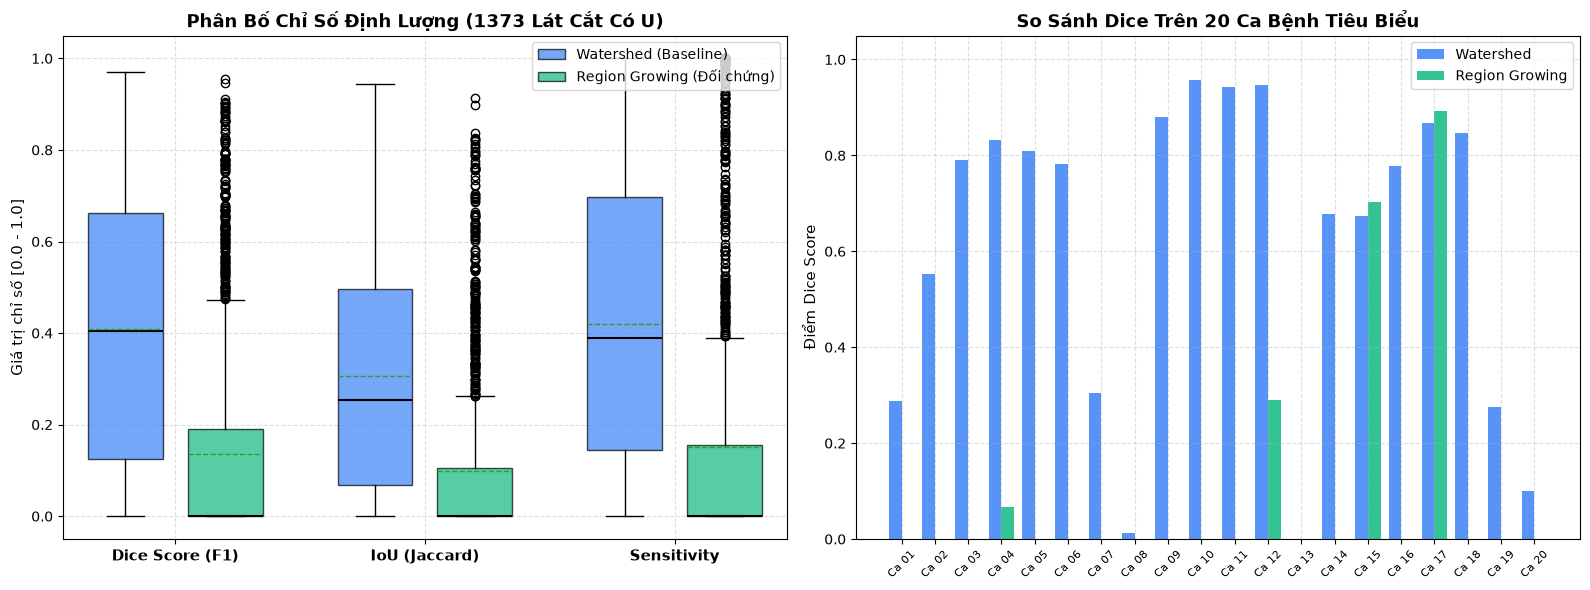

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot so sánh phân bố chỉ số y khoa trên toàn bộ lát cắt có u
metrics_data_ws = [eval_ws['dice'], eval_ws['iou'], eval_ws['sensitivity']]
metrics_data_rg = [eval_rg['dice'], eval_rg['iou'], eval_rg['sensitivity']]

box1 = ax1.boxplot(metrics_data_ws, positions=[1, 3, 5], widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor='#3B82F6', alpha=0.7),
                   medianprops=dict(color='black', linewidth=1.5),
                   showmeans=True, meanline=True)
box2 = ax1.boxplot(metrics_data_rg, positions=[1.8, 3.8, 5.8], widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor='#10B981', alpha=0.7),
                   medianprops=dict(color='black', linewidth=1.5),
                   showmeans=True, meanline=True)

ax1.set_xticks([1.4, 3.4, 5.4])
ax1.set_xticklabels(['Dice Score (F1)', 'IoU (Jaccard)', 'Sensitivity'], fontsize=11, fontweight='bold')
ax1.set_ylabel('Giá trị chỉ số [0.0 - 1.0]', fontsize=11)
ax1.set_title(f'Phân Bố Chỉ Số Định Lượng ({len(eval_ws)} Lát Cắt Có U)', fontsize=13, fontweight='bold')
ax1.legend([box1['boxes'][0], box2['boxes'][0]], ['Watershed (Baseline)', 'Region Growing (Đối chứng)'], loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.set_ylim(-0.05, 1.05)

# 2. Bar chart so sánh trên 20 ca mẫu đại diện
sample_n = min(20, len(eval_ws))
sample_ws = eval_ws.iloc[:sample_n]
sample_rg = eval_rg.iloc[:sample_n]
x = np.arange(sample_n)
width = 0.38

ax2.bar(x - width/2, sample_ws['dice'], width, label='Watershed', color='#3B82F6', alpha=0.85)
ax2.bar(x + width/2, sample_rg['dice'], width, label='Region Growing', color='#10B981', alpha=0.85)
ax2.set_ylabel('Điểm Dice Score', fontsize=11)
ax2.set_title(f'So Sánh Dice Trên {sample_n} Ca Bệnh Tiêu Biểu', fontsize=13, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels([f'Ca {i+1:02d}' for i in range(sample_n)], rotation=45, fontsize=8)
ax2.legend()
ax2.set_ylim(0, 1.05)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/benchmark_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Phân Tích Trường Hợp Thất Bại (Failure Cases Analysis)
Theo yêu cầu bắt buộc của Khung tổng quát (Mục II.6): Phải chỉ ra và lý giải nguyên nhân sai lệch.

3 Ca bệnh khó nhất / có điểm Dice thấp nhất:
                     sample_id  dice_ws  dice_rg  min_dice
3859  TCGA_HT_A61B_19991127_26   0.0000      0.0       0.0
3869  TCGA_HT_A61B_19991127_35   0.6332      0.0       0.0
2     TCGA_CS_4941_19960909_11   0.2876      0.0       0.0


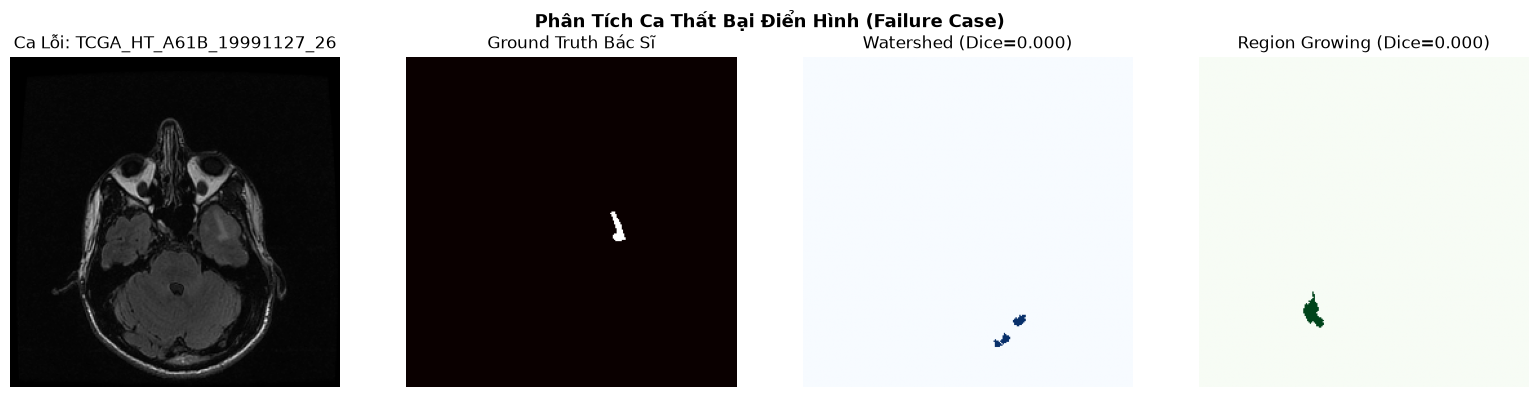


NHẬN XÉT NGUYÊN NHÂN THẤT BẠI (ĐƯA VÀO BÁO CÁO):
1. Khối u có độ tương phản quá thấp so với chất xám xung quanh (ranh giới bờ mờ).
2. Kích thước u quá nhỏ khiến bản đồ khoảng cách Euclidean (Distance Transform) bị suy biến đỉnh cực đại.
3. Hướng khắc phục: Cần kết hợp thêm thông tin kết cấu GLCM hoặc sử dụng ngưỡng thích ứng cục bộ.



In [5]:
# Tìm các ca có khối u thực sự nhưng có điểm Dice thấp nhất (Failure cases)
if 'has_tumor_gt' in df_ws.columns:
    df_compare = pd.DataFrame({
        'sample_id': eval_ws['sample_id'],
        'dice_ws': eval_ws['dice'],
        'dice_rg': eval_rg['dice']
    })
else:
    df_compare = pd.DataFrame({
        'sample_id': df_ws['sample_id'],
        'dice_ws': df_ws['dice'],
        'dice_rg': df_rg['dice']
    })

df_compare['min_dice'] = df_compare[['dice_ws', 'dice_rg']].min(axis=1)
worst_cases = df_compare.sort_values(by='min_dice').head(3)

print('3 Ca bệnh khó nhất / có điểm Dice thấp nhất:')
print(worst_cases)

# Hiển thị trực quan ca lỗi nặng nhất
worst_id = worst_cases.iloc[0]['sample_id']
w_img = cv2.imread(os.path.join(img_dir, f'{worst_id}.png'), cv2.IMREAD_GRAYSCALE)
w_gt = cv2.imread(os.path.join(mask_dir, f'{worst_id}_mask.png'), cv2.IMREAD_GRAYSCALE)
w_stripped, _ = strip_skull(w_img)
w_pred_ws = segment_watershed(w_stripped)
w_pred_rg = segment_region_growing(w_stripped)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(w_img, cmap='gray'); axes[0].set_title(f'Ca Lỗi: {worst_id}'); axes[0].axis('off')
axes[1].imshow(w_gt, cmap='hot'); axes[1].set_title('Ground Truth Bác Sĩ'); axes[1].axis('off')
axes[2].imshow(w_pred_ws, cmap='Blues'); axes[2].set_title(f"Watershed (Dice={worst_cases.iloc[0]['dice_ws']:.3f})"); axes[2].axis('off')
axes[3].imshow(w_pred_rg, cmap='Greens'); axes[3].set_title(f"Region Growing (Dice={worst_cases.iloc[0]['dice_rg']:.3f})"); axes[3].axis('off')
plt.suptitle('Phân Tích Ca Thất Bại Điển Hình (Failure Case)', fontsize=13, fontweight='bold')
plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/benchmark_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print('''
NHẬN XÉT NGUYÊN NHÂN THẤT BẠI (ĐƯA VÀO BÁO CÁO):
1. Khối u có độ tương phản quá thấp so với chất xám xung quanh (ranh giới bờ mờ).
2. Kích thước u quá nhỏ khiến bản đồ khoảng cách Euclidean (Distance Transform) bị suy biến đỉnh cực đại.
3. Hướng khắc phục: Cần kết hợp thêm thông tin kết cấu GLCM hoặc sử dụng ngưỡng thích ứng cục bộ.
''')